# pca.ipynb

[Gemini chat](https://share.gemini.google/hEE7wGm723l1)

In [1]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import sqlite3
import pandas as pd
from shapely import wkb
import os
import cv2
import matplotlib.pyplot as plt
from icecream import ic

In [2]:
db_path = db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'

## Data

In [3]:
# Open database
db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'
conn = sqlite3.connect(db_path)  
conn.row_factory = sqlite3.Row  # Enable named column access 
conn.enable_load_extension(True)
conn.load_extension('mod_spatialite')
cursor = conn.cursor()

sample_size = 10
sql = f'''  
SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_bin, AsSVG(tree_poly) AS svg, 
  MbrMinX(tree_poly) AS minx, -MbrMinY(tree_poly) AS miny, MbrMaxX(tree_poly) AS maxx, -MbrMaxY(tree_poly) as maxy
FROM trees 
WHERE tree_touches_edge=0
ORDER BY RANDOM() 
LIMIT {sample_size}
'''
df = pd.read_sql(sql, conn)
   
#     rows = cursor.execute(sql).fetchall()
#     for row in rows:
#         poly = wkb.loads(row['tree_poly_bin']) 
#         exterior_coords = np.array(poly.exterior.coords, dtype=np.int32)
#         exterior_coords = np.abs(exterior_coords)  # Ensure all coordinates are positive
#         moments = cv2.moments(exterior_coords)
        
#         # Compute Hu moments and apply log transformation (e.g., signed log)
#         hu_moments = cv2.HuMoments(moments).flatten()
#         lhus = np.sign(hu_moments) * np.log10(np.abs(hu_moments) + 1e-15)
        
#         s += f'{row["tree_id"]},{row["image_id"]},{row["confidence"]},{row["pixel_count"]},{row["tree_class"]}'  
#         for lhu in lhus:
#             s += f',{lhu:.4f}'
#         s += '\n'       
#     with open('pca_data.csv', 'w', encoding='utf-8') as f:
#         f.write(s)   
#     conn.close()
#     print(f'A new training set CSV has been created at {csv_path}')
# else:
#     print(f'WARNING: The training set CSV already exists at {csv_path}. Skipping.')
conn.close()
df


,tree_id,image_id,confidence,pixel_count,tree_class,tree_poly_bin,svg,minx,miny,maxx,maxy
0,3288,505,0.290039,2013.0,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\xbe\x00...,M 596 535 L 594 537 594 538 593 539 593 545 59...,550.0,773.0,601.0,535.0
1,21930,3250,0.426270,1695.0,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00q\x00\x0...,M 1435 661 L 1434 662 1433 662 1432 663 1432 6...,1423.0,830.0,1460.0,661.0
2,23534,3487,0.632324,12795.5,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00_\x01\x0...,M 1219 339 L 1219 340 1218 341 1218 343 1217 3...,1094.0,515.0,1266.0,339.0
3,14944,2221,0.421387,825.5,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00.\x00\x0...,M 1303 875 L 1302 876 1302 877 1301 878 1301 8...,1301.0,917.0,1329.0,875.0
4,14042,2064,0.345947,2026.5,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x9b\x00...,M 1733 823 L 1732 824 1731 824 1727 828 1722 8...,1710.0,934.0,1749.0,823.0
5,21229,3099,0.849121,25963.5,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\xe5\x03...,M 1590 378 L 1586 382 1586 383 1583 386 1582 3...,1430.0,983.0,1695.0,378.0
6,11818,1751,0.871094,32910.5,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x002\x03\x0...,M 407 462 L 406 463 405 463 405 468 406 469 40...,236.0,810.0,569.0,462.0
7,24341,3580,0.287354,1515.0,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00d\x00\x0...,M 203 840 L 203 841 202 842 202 846 203 847 20...,182.0,955.0,210.0,840.0
8,3464,531,0.268799,4638.0,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\xf8\x00...,M 477 850 L 476 851 475 851 475 853 473 855 46...,414.0,936.0,516.0,850.0
9,1601,266,0.911133,20025.0,None,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00#\x03\x0...,M 1406 107 L 1405 108 1402 108 1401 109 1401 1...,1398.0,1079.0,1616.0,107.0


In [4]:
# Compute Hu moments and apply log transformation (e.g., signed log)
lhus_list = []
for r in df.itertuples():
    poly = wkb.loads(r.tree_poly_bin) 
    exterior_coords = np.array(poly.exterior.coords, dtype=np.int32)
    exterior_coords = np.abs(exterior_coords)  # Ensure all coordinates are positive
    moments = cv2.moments(exterior_coords)
    hu_moments = cv2.HuMoments(moments).flatten()
    lhus = np.sign(hu_moments) * np.log10(np.abs(hu_moments) + 1e-15)
    lhus_list.append({'tree_id': r.tree_id, 'h1': lhus[0], 'h2': lhus[1], 'h3': lhus[2], 'h4': lhus[3], 'h5': lhus[4], 'h6': lhus[5], 'h7': lhus[6]}) 
df_hu = pd.DataFrame(lhus_list)
df_hu

,tree_id,h1,h2,h3,h4,h5,h6,h7
0,3288,0.376328,0.750436,-1.079530,-1.089211,-2.173582,-0.714108,-5.586785
1,21930,0.099595,0.158995,0.262134,0.216493,0.455793,0.295979,-1.641586
2,23534,-0.570623,-1.695107,-2.140033,-2.634002,-5.067210,-3.593488,5.379806
3,14944,-0.689212,-1.890958,-3.006183,-3.885360,-7.337036,-4.847317,8.116877
4,14042,-0.324337,-0.744028,-2.137082,-2.875554,-5.792785,4.560951,-5.417347
5,21229,-0.051102,-0.209682,0.180691,0.118701,0.268359,0.013852,-1.604179
6,11818,-0.532509,-3.804288,-1.938673,-2.759318,-5.224245,-4.678678,5.299984
7,24341,-0.308361,-0.702231,-1.525617,-1.663881,-3.258757,-2.015058,4.873116
8,3464,-0.683326,-2.540464,-3.088938,-5.945636,-11.396430,-8.130892,10.465879
9,1601,0.583451,1.164798,0.096677,0.091770,0.185994,0.673629,-3.253549


In [5]:
log_hu = df_hu[['h1', 'h2', 'h3', 'h4', 'h5', 'h6', 'h7']]
labels = df_hu[['tree_id']]

# 2. Standardize to zero mean and unit variance
scaler = StandardScaler()
scaled_hu = scaler.fit_transform(log_hu)

# 3. Apply PCA for visualization
pca = PCA(n_components=2)
pca_results = pca.fit_transform(scaled_hu)
variance = pca.explained_variance_ratio_ * 100

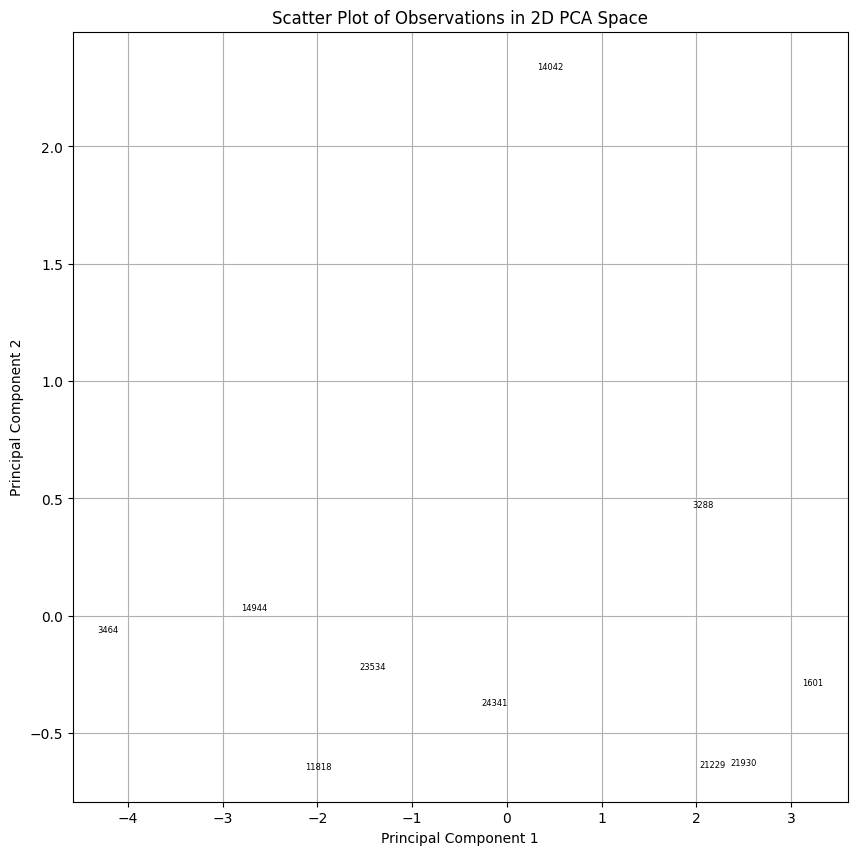

In [6]:
# Create a scatter plot to visualize the observations in the 2D PCA space
plt.figure(figsize=(10, 10))
plt.scatter(pca_results[:, 0], # position on the first principal component of the observations
            pca_results[:, 1], alpha=0.0) # position on the second principal component of the observations

# Add title and axis label
plt.title('Scatter Plot of Observations in 2D PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# # (optionally) Add labels to each point based on their index in the original dataframe
for i, txt in enumerate(df.tree_id):
    plt.annotate(txt, (pca_results[i, 0], pca_results[i, 1]), fontsize=6, ha='center', va='center')
    # This might be useful when doing outlier detection

# Add grid in the background
plt.grid(True)

# Display the chart
plt.show()

In [7]:
for r in df.itertuples():
    tree_id = r.tree_id
    svg = r.svg 
    s = r.svg
    break
s_list = s.split()
ic(s_list[:10])
ic(s_list[-10:])
first = s_list.index('L') + 1
last = s_list.index('z')
s_list1 = s_list[first:last]
ic(s_list1[:2])
ic(s_list1[-2:])

xs = s_list1[::2]
ys = s_list1[1::2]
ic(min(xs), max(xs))
ic(min(ys), max(ys))



ic| s_list[:10]: ['M', '596', '535', 'L', '594', '537', '594', '538', '593', '539']
ic| s_list[-10:]: ['538', '600', '537', '600', '536', '599', '536', '598', '535', 'z']
ic| s_list1[:2]: ['594', '537']
ic| s_list1[-2:]: ['598', '535']
ic| min(xs): '550', max(xs): '601'
ic| min(ys): '535', max(ys): '773'


('535', '773')

# Transforming a SVG so that it is square with a centred path

Here is an 600x500 pixel SVG containing a triangle which is slightly taller than its width.
Note that the path uses relative coordinates.

The goal is to transform this SVG to 40x40 pixels.

```svg
<svg height="500" width="600" xmlns="http://www.w3.org/2000/svg">
  <path d="M 200 0 l 180 400 -360 0 180 -400 0 Z" />  
</svg>
```

In [8]:
from svg.path import parse_path

target_size = 40
tree_id = 10654

# Open database
db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'
conn = sqlite3.connect(db_path)  
conn.row_factory = sqlite3.Row  # Enable named column access 
conn.enable_load_extension(True)
conn.load_extension('mod_spatialite')
cursor = conn.cursor()

# get svg path for a specified tree_id
sql = f'SELECT tree_id, AsSVG(tree_poly) AS svg FROM trees WHERE tree_id={tree_id}'
row = cursor.execute(sql).fetchone()
tree_id = row['tree_id']
tree_path = row['svg']
ic(tree_path)

# get data for transform
path = parse_path(row['svg'])
# path = parse_path("M 200 0 l 180 400 -360 0 180 -400 0 Z")

xmin, ymin, xmax, ymax = path.boundingbox()
ic(xmin, ymin, xmax, ymax)
width = xmax - xmin
height = ymax - ymin
max_dim = max(width, height)
scale_factor = target_size / max_dim
ic(width, height, max_dim, scale_factor);

xcenter = xmin + (width / 2.0)
ycenter = ymin + (height / 2.0)
ic(xcenter,ycenter);

# construct transformed svg
svg_str = f'<svg height="{target_size}" width="{target_size}" xmlns="http://www.w3.org/2000/svg"><path d="{tree_path}" transform="scale({scale_factor}) translate({-xcenter+40} {-ycenter+40})" /></svg>'
ic(svg_str)
with open("output.svg", "w") as f:
  f.write(svg_str)

ic| tree_path: 'M 1037 653 L 1030 660 1030 667 1029 668 1029 669 1030 670 1030 679 1031 680 1031 684 1030 685 1031 686 1031 690 1030 691 1030 692 1029 693 1029 694 1030 695 1029 696 1029 697 1028 698 1028 704 1029 705 1029 709 1027 711 1026 711 1024 713 1024 716 1025 717 1025 719 1024 720 1024 722 1025 723 1025 724 1026 725 1026 727 1027 728 1027 731 1026 732 1026 734 1027 735 1027 736 1025 738 1025 740 1024 741 1024 743 1023 744 1023 745 1024 746 1024 751 1022 753 1022 755 1023 756 1025 756 1026 757 1027 757 1028 758 1026 760 1026 765 1025 766 1025 767 1024 768 1024 770 1023 771 1023 772 1026 775 1026 778 1027 779 1027 783 1026 784 1026 786 1027 787 1027 788 1026 789 1026 790 1025 791 1025 793 1026 793 1027 794 1031 794 1032 793 1032 792 1028 788 1028 787 1030 785 1030 783 1033 780 1036 780 1038 782 1038 783 1036 785 1038 787 1037 788 1037 789 1036 790 1036 792 1035 793 1036 794 1036 795 1035 796 1035 797 1036 798 1036 802 1037 803 1037 806 1036 807 1036 815 1035 816 1035 823 1036 824

In [9]:
import xml.etree.ElementTree as ET
from svgpathtools import parse_path


def fit_path_to_square(
    path_d: str, canvas_size: int = 512, padding: int = 20
) -> str:
  """Scales and centers an SVG path string to fit within a square canvas.

  Args:
      path_d: The 'd' attribute string from an SVG <path> element.
      canvas_size: The width and height of the target square image in pixels.
      padding: Margin in pixels to leave around the scaled path.

  Returns:
      The transformed SVG 'd' attribute string.
  """
  path = parse_path(path_d)

  # 1. Get the exact bounding box (xmin, xmax, ymin, ymax)
  xmin, xmax, ymin, ymax = path.bbox()
  width = xmax - xmin
  height = ymax - ymin

  if width == 0 or height == 0:
    return path_d

  # 2. Calculate the uniform scale factor to fit within the padded area
  target_size = canvas_size - (2 * padding)
  scale = min(target_size / width, target_size / height)

  # 3. Shift the path so its top-left bounding box corner sits at (0, 0)
  path = path.translated(complex(-xmin, -ymin))

  # 4. Scale the path uniformly
  path = path.scaled(scale)

  # 5. Calculate offsets to center the scaled path in the square canvas
  new_width = width * scale
  new_height = height * scale
  offset_x = (canvas_size - new_width) / 2
  offset_y = (canvas_size - new_height) / 2

  # 6. Translate the path to the center
  centered_path = path.translated(complex(offset_x, offset_y))

  return centered_path.d()


def create_centered_svg_file(
    path_d: str, output_filename: str, canvas_size: int = 512, padding: int = 20
):
  """Generates a complete, valid SVG file containing the centered path."""
  transformed_d = fit_path_to_square(path_d, canvas_size, padding)

  # Build the SVG XML structure
  svg = ET.Element(
      "svg",
      {
          "xmlns": "http://www.w3.org/2000/svg",
          "width": str(canvas_size),
          "height": str(canvas_size),
          "viewBox": f"0 0 {canvas_size} {canvas_size}",
      },
  )

  ET.SubElement(
      svg,
      "path",
      {
          "d": transformed_d,
          "fill": "#000000",
      },
  )

  tree = ET.ElementTree(svg)
  ET.indent(tree, space="  ")
  tree.write(output_filename, encoding="utf-8", xml_declaration=True)
  print(f"Saved centered SVG to {output_filename}")


# --- Example Usage ---
if __name__ == "__main__":
  # An off-center, tiny triangle path
#   raw_path = "M 150 200 L 170 200 L 160 180 Z"

#   # Transform and save into a 500x500 square with 40px padding
#   create_centered_svg_file(
#       path_d=raw_path,
#       output_filename="centered_output.svg",
#       canvas_size=500,
#       padding=40,
#   )

  create_centered_svg_file(
      path_d=tree_path,
      output_filename="centered_output.svg",
      canvas_size=40,
      padding=0,
  )

Saved centered SVG to centered_output.svg
